 THEN THE MOTHER LIFTED UP HER VOICE AND WEPT


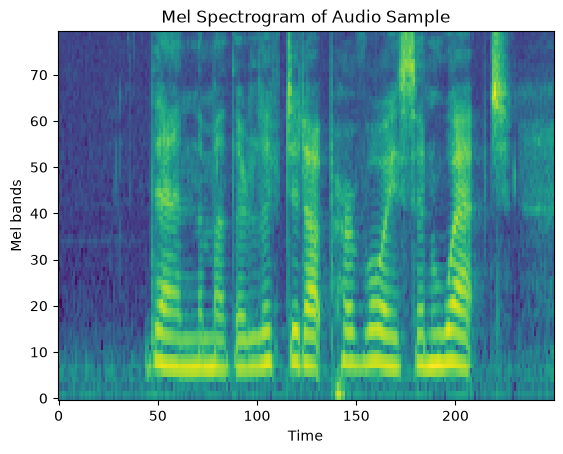

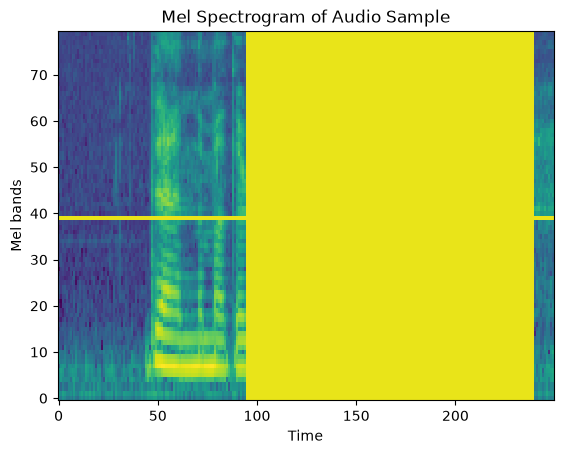

In [14]:
import torch
import torchaudio
from torchaudio.transforms import MelSpectrogram, AmplitudeToDB
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from pathlib import Path

class LibriSpeech(Dataset):
  def __init__(self, base_path, set_type):
    self.mel_transform = MelSpectrogram(sample_rate=16000, n_fft=400, n_mels=80)
    self.db_transform = AmplitudeToDB("power", 80.0)

    self.root_dir = Path(f"{base_path}/{set_type}")
    files = [p for p in self.root_dir.rglob("*") if p.is_file() and not p.name.endswith(".txt")]
    self.audio_paths = list(sorted(files))
    self.transcript_cache = {}

  def get_transcript(self, audio_path):
    name, _ = audio_path.name.split(".")
    s, c, i = name.split("-")[-3:]
    transcript_path = f"{self.root_dir}/{s}/{c}/{s}-{c}.trans.txt"

    if transcript_path in self.transcript_cache:
      lines = self.transcript_cache[transcript_path]
      return lines[int(i)][len(name):]

    with open(transcript_path, "r") as file:
      lines = file.read().split("\n")
      self.transcript_cache[transcript_path] = lines
      return lines[int(i)][len(name):]

  def __len__(self):
    return len(self.audio_paths)

  def __getitem__(self, idx):
    waveform, sample_rate = torchaudio.load(self.audio_paths[idx])
    assert sample_rate == 16000 # As desribed by the dataset
    spectrogram = self.db_transform(self.mel_transform(waveform))
    transcript = self.get_transcript(self.audio_paths[idx])
    return spectrogram, transcript

def mask_spectrogram(spectrogram, max_time_mask, max_freq_mask):
  _, height, width = spectrogram.shape
  time_len = torch.randint(0, max_time_mask, size=(1,))
  band_len = torch.randint(0, max_freq_mask, size=(1,))
  time_idx = torch.randint(0, width - time_len, size=(1,))
  band_idx = torch.randint(0, height - band_len, size=(1,))
  masked = spectrogram.detach().clone()
  masked[:, band_idx:band_idx + band_len, :] = 0
  masked[:, :, time_idx:time_idx + time_len] = 0
  return masked

def plot_spectrogram(spectrogram):
  _, ax = plt.subplots(1, 1)
  ax.set_title("Mel Spectrogram of Audio Sample")
  ax.set_ylabel("Mel bands")
  ax.set_xlabel("Time")
  ax.imshow(spectrogram.permute(1, 2, 0), origin="lower", aspect="auto", interpolation="nearest")

dataset = LibriSpeech(".cache/LibriSpeech", "dev-clean")
loader = DataLoader(dataset, shuffle=True, batch_size=1)

spectrograms, labels = next(iter(loader))
label, spectrogram = labels[0], spectrograms[0]
masked = mask_spectrogram(spectrogram, 240, 4)

print(label)
plot_spectrogram(spectrogram)
plot_spectrogram(masked)

TODO:
- Process audio samples in chunks, since track length is variable
- Load model weights for nvidia's parkeet model
- First run a demo to visualize the mel spectrogram for each sample chunk